
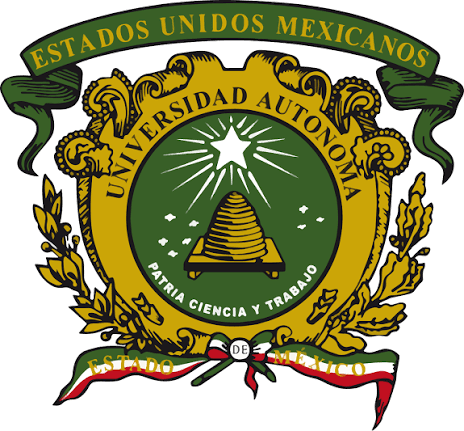

In [1]:
from pathlib import Path
from base64 import b64encode
from IPython.display import HTML, display

# Edita aquí los datos de la portada.
campus = "Centro Universitario UAEM Zumpango"
semestre = "5.º semestre"
turno = "Turno matutino"
asignatura = "Investigación de Operaciones"
practica = "Práctica 3 · Algoritmo de Dijkstra"
proyecto = "Ruta más corta en la red del centro universitario"

integrantes = [
    "Daniela Cacahuatitla García",
    "Alexander Garcia Gonzales",
    "Rafael Mimbrera Moreno"
]

# Insertar el escudo dentro de la portada.
archivo_escudo = Path("escudo_uaem.png")

if archivo_escudo.is_file():
    imagen = b64encode(archivo_escudo.read_bytes()).decode("ascii")
    escudo = (
        f'<img src="data:image/png;base64,{imagen}" '
        'alt="Escudo de la UAEMéx" '
        'style="width:120px; max-width:27%; height:auto;">'
    )
else:
    escudo = '<div style="color:#2e501d; font-weight:bold;">UAEMéx</div>'

nombres = "<br>".join(integrantes)

portada = f"""
<div style="
    box-sizing:border-box;
    position:relative;
    max-width:760px;
    min-height:790px;
    margin:16px auto;
    padding:52px 35px 50px 65px;
    background:#ffffff;
    color:#171717;
    font-family:Arial, sans-serif;
    text-align:center;
    border:1px solid #dddddd;
">
    <div style="
        position:absolute; top:0; bottom:0; left:0;
        width:30px; background:#2e501d;
        border-right:10px solid #aa8b30;
    "></div>

    <div style="
        display:flex; align-items:center; justify-content:center;
        gap:20px; margin-bottom:45px;
    ">
        {escudo}
        <div style="font-size:20px; font-weight:bold; line-height:1.35;">
            Universidad Autónoma del Estado de México
        </div>
    </div>

    <div style="font-size:17px; font-weight:bold; color:#2e501d;">
        {campus.upper()}
    </div>

    <div style="margin-top:36px; font-size:16px; line-height:1.8;">
        <strong>{semestre}</strong><br>
        {turno}
    </div>

    <div style="margin-top:32px; font-size:18px; font-weight:bold;">
        {asignatura}
    </div>

    <h1 style="margin:14px 0 8px; font-size:28px; color:#2e501d;">
        {practica}
    </h1>

    <div style="font-size:17px;">{proyecto}</div>

    <div style="margin-top:44px; font-size:16px; line-height:1.8;">
        <strong>Integrantes</strong><br>
        {nombres}
    </div>
</div>
"""

display(HTML(portada))

## Planteamiento del problema

En el Centro Universitario UAEM Zumpango existen distintos recorridos posibles para trasladarse del edificio administrativo a la cafetería. Para esta práctica, se desea identificar qué recorrido permitiría llegar a la cafetería caminando la menor distancia total. La pregunta es qué áreas se deben atravesar y cuántos metros se recorren al seguir ese trayecto.

Para representar el problema se reutilizará la red de ocho nodos construida en la Práctica 1. Los nodos corresponden a distintas áreas del centro universitario. El edificio administrativo se representa con el nodo **A**, que será el origen, y la cafetería con el nodo **H**, que será el destino. Las demás áreas pueden funcionar como puntos intermedios del recorrido.

Cada enlace representa un trayecto directo entre dos áreas y tiene un peso que indica su longitud en metros. La red es un **grafo no dirigido**, porque cada trayecto puede recorrerse en ambos sentidos con la misma distancia. Las longitudes son hipotéticas y se utilizarán como datos para el ejercicio.

Para comparar los recorridos posibles se debe sumar la longitud de todos los enlaces de cada ruta. Por ejemplo, el enlace de A a B mide 10 metros, pero seguir de B a C agrega otros 12 metros. Por lo tanto, el recorrido A–B–C suma 22 metros, mientras que el trayecto directo de A a C mide 14 metros. Esta comparación muestra por qué, al evaluar una ruta, se debe considerar la **distancia acumulada desde el origen**.

### Objetivo

Aplicar el algoritmo de Dijkstra para determinar la ruta de menor distancia entre el nodo A y el nodo H. Al finalizar, se indicará el orden de los nodos que forman la ruta y se calculará la distancia total del recorrido.

El algoritmo es adecuado para esta red porque todos los enlaces tienen pesos positivos. El procedimiento comenzará asignando una distancia de cero al nodo A. En cada iteración se elegirá el nodo pendiente con la menor distancia provisional y se revisará si pasar por él permite mejorar la distancia hacia alguno de sus vecinos. Cuando se encuentre un recorrido más corto hacia un nodo, se actualizará su distancia y se guardará el nodo anterior para poder reconstruir la ruta.

Una vez que la distancia hasta H sea definitiva, se seguirá la secuencia de predecesores desde la cafetería hasta el edificio administrativo. Después se invertirá esa secuencia para presentar el recorrido de A a H. Finalmente, se resaltará la ruta en una gráfica y se verificará su longitud sumando los pesos de los enlaces que la componen.

## Construcción de la red

La red tiene ocho nodos y once enlaces. Los nodos representan áreas
del centro universitario. El número sobre cada enlace indica la
distancia en metros.

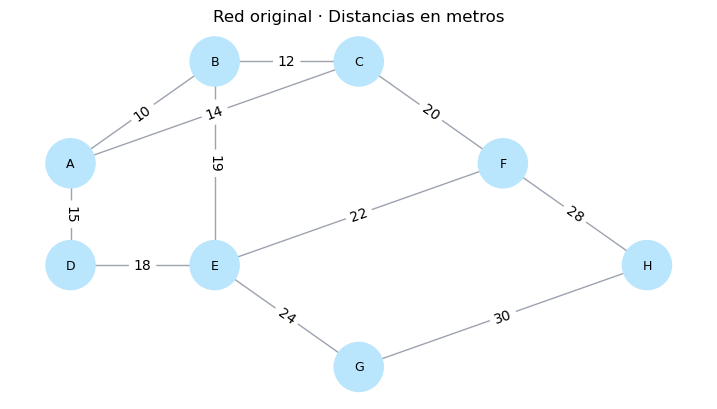

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

enlaces = [
    ("A", "B", 10), ("B", "C", 12), ("A", "C", 14),
    ("A", "D", 15), ("D", "E", 18), ("B", "E", 19),
    ("C", "F", 20), ("E", "F", 22), ("E", "G", 24),
    ("F", "H", 28), ("G", "H", 30)
]

red = nx.Graph()
red.add_weighted_edges_from(enlaces)

posiciones = {
    "A": (0, 1), "B": (1, 2), "C": (2, 2), "D": (0, 0),
    "E": (1, 0), "F": (3, 1), "G": (2, -1), "H": (4, 0)
}

def dibujar_red(titulo, etiquetas=None, visitados=(), ruta=()):
    plt.figure(figsize=(9, 4.8))
    colores = ["#86efac" if nodo in visitados else "#bae6fd" for nodo in red]

    nx.draw_networkx(
        red, posiciones, labels=etiquetas, node_color=colores,
        node_size=1250, font_size=9, edge_color="#9ca3af"
    )
    nx.draw_networkx_edge_labels(
        red, posiciones, edge_labels=nx.get_edge_attributes(red, "weight")
    )

    if ruta:
        nx.draw_networkx_edges(
            red, posiciones, edgelist=list(zip(ruta, ruta[1:])),
            edge_color="#15803d", width=3
        )

    plt.title(titulo)
    plt.axis("off")
    plt.show()

dibujar_red("Red original · Distancias en metros")

## Aplicación del algoritmo de Dijkstra

Al inicio, A tiene distancia 0 y los demás nodos tienen distancia infinita.
En cada iteración se elige el nodo pendiente con la menor distancia
provisional y se marca como definitivo. Después se revisan sus vecinos.

Para cada vecino se suma la distancia del nodo actual y el peso del
enlace. Si la suma mejora la distancia provisional del vecino, se
actualiza ese valor y se guarda el nodo actual como su predecesor.

Cada gráfica muestra en verde los nodos con distancia definitiva.
El algoritmo termina cuando H queda marcado como definitivo.

Paso 1 · Nodo definitivo: A
Actualizaciones: B = 10 m, C = 14 m, D = 15 m


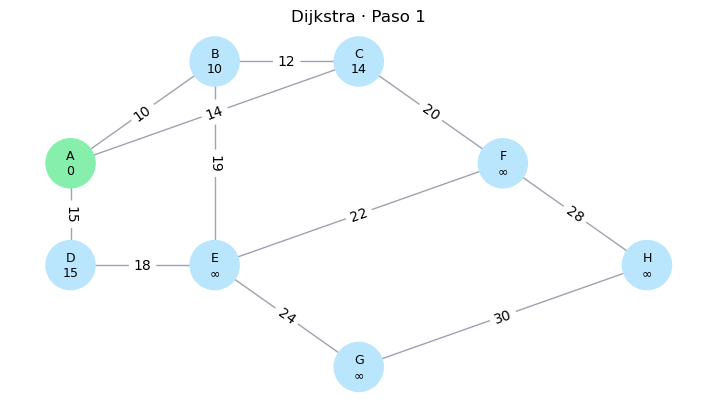

Paso 2 · Nodo definitivo: B
Actualizaciones: E = 29 m


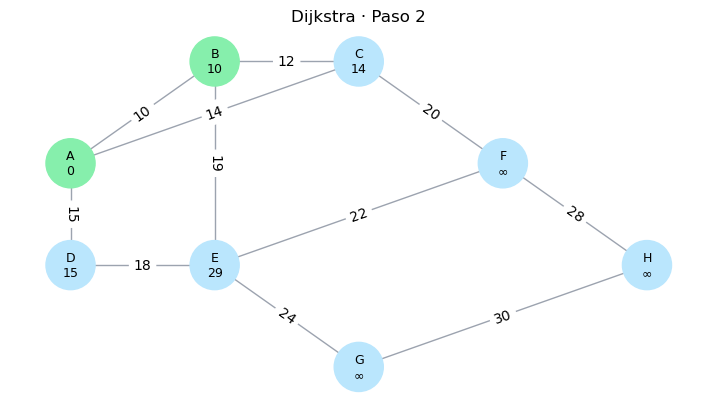

Paso 3 · Nodo definitivo: C
Actualizaciones: F = 34 m


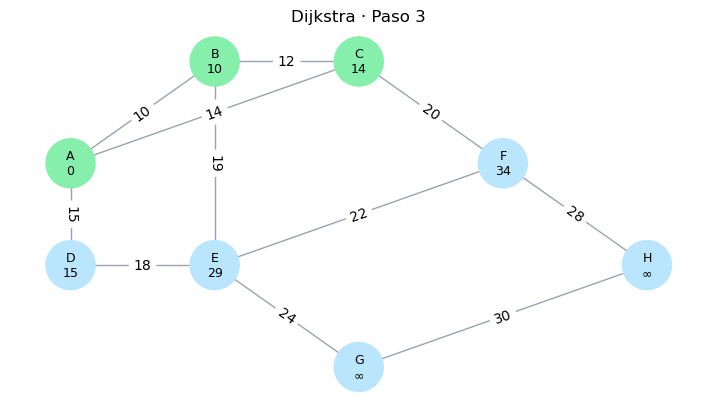

Paso 4 · Nodo definitivo: D
Actualizaciones: Ninguna


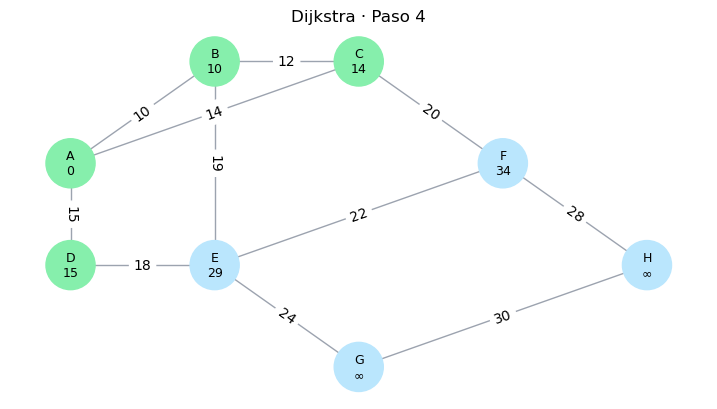

Paso 5 · Nodo definitivo: E
Actualizaciones: G = 53 m


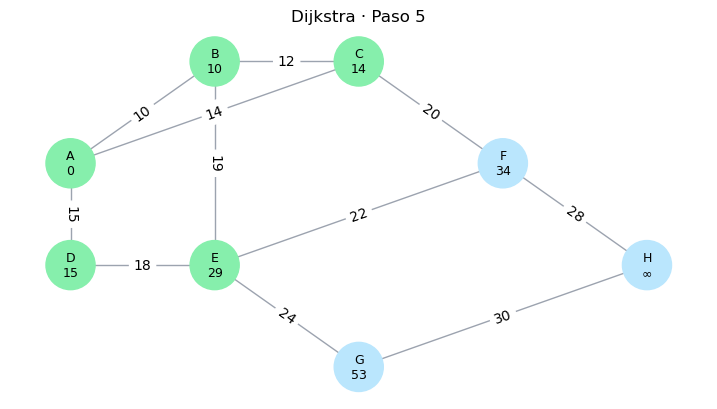

Paso 6 · Nodo definitivo: F
Actualizaciones: H = 62 m


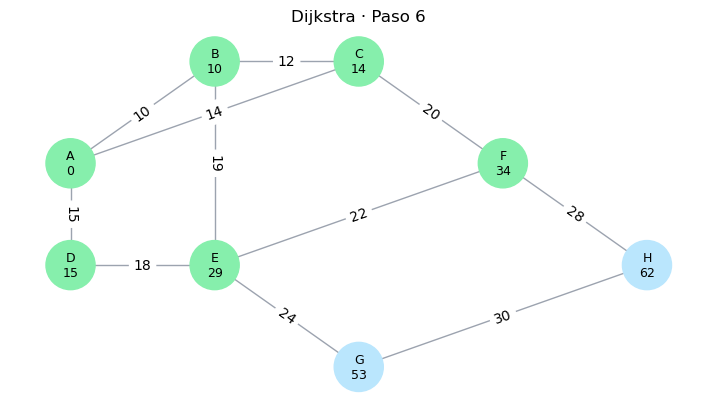

Paso 7 · Nodo definitivo: G
Actualizaciones: Ninguna


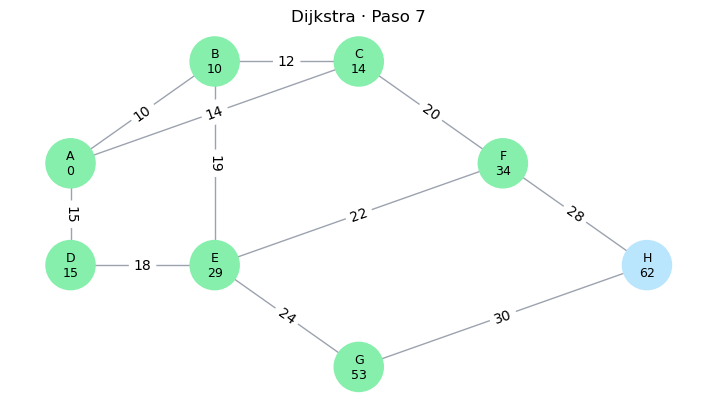

Paso 8 · Nodo definitivo: H
Actualizaciones: Ninguna


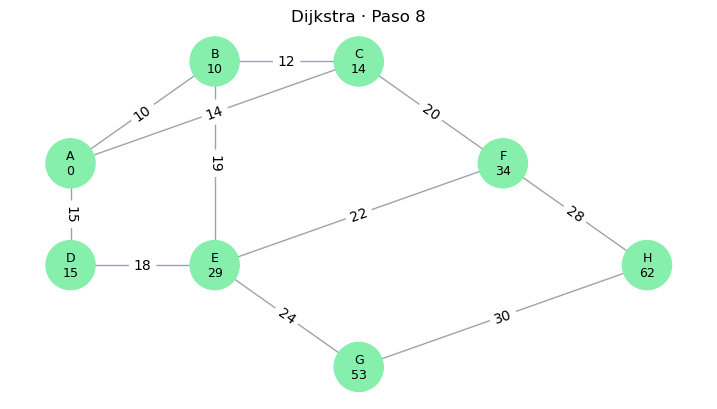

,Paso,Nodo definitivo,Distancia desde A (m),Distancias actualizadas
0,1,A,0,"B = 10 m, C = 14 m, D = 15 m"
1,2,B,10,E = 29 m
2,3,C,14,F = 34 m
3,4,D,15,Ninguna
4,5,E,29,G = 53 m
5,6,F,34,H = 62 m
6,7,G,53,Ninguna
7,8,H,62,Ninguna


In [4]:
origen, destino = "A", "H"
infinito = float("inf")
distancias = {nodo: infinito for nodo in red}
predecesores = {}
visitados = set()
registro = []

distancias[origen] = 0

while destino not in visitados:
    pendientes = set(red) - visitados
    actual = min(pendientes, key=lambda nodo: (distancias[nodo], nodo))
    visitados.add(actual)

    cambios = []
    for vecino, datos in red[actual].items():
        nueva_distancia = distancias[actual] + datos["weight"]
        if vecino not in visitados and nueva_distancia < distancias[vecino]:
            distancias[vecino] = nueva_distancia
            predecesores[vecino] = actual
            cambios.append(f"{vecino} = {nueva_distancia} m")

    etiquetas = {
        nodo: f"{nodo}\n{'∞' if valor == infinito else valor}"
        for nodo, valor in distancias.items()
    }

    registro.append({
        "Paso": len(visitados),
        "Nodo definitivo": actual,
        "Distancia desde A (m)": distancias[actual],
        "Distancias actualizadas": ", ".join(cambios) or "Ninguna"
    })

    print(f"Paso {len(visitados)} · Nodo definitivo: {actual}")
    print("Actualizaciones:", ", ".join(cambios) or "Ninguna")
    dibujar_red(f"Dijkstra · Paso {len(visitados)}", etiquetas, visitados)

display(pd.DataFrame(registro))

## Reconstrucción de la ruta más corta

Para reconstruir la ruta, comenzamos en H y seguimos los predecesores
hasta llegar a A. Después invertimos el orden. Verificamos la distancia
con la función de Dijkstra de NetworkX.

Ruta más corta: A → C → F → H
Distancia total: 62 metros


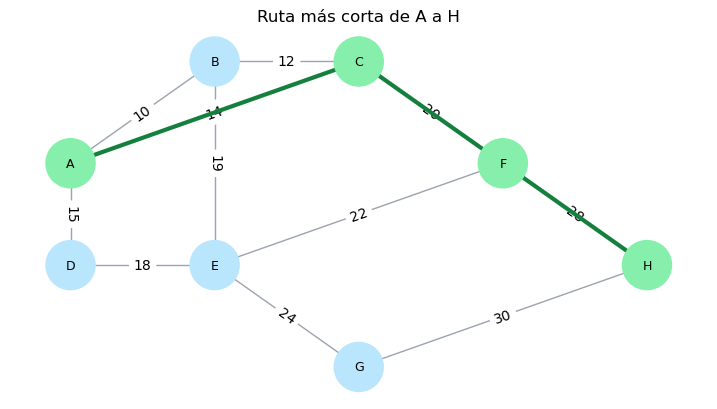

In [5]:
ruta = [destino]

while ruta[-1] != origen:
    ruta.append(predecesores[ruta[-1]])

ruta.reverse()
distancia_total = distancias[destino]

assert distancia_total == nx.dijkstra_path_length(red, origen, destino)

print("Ruta más corta:", " → ".join(ruta))
print(f"Distancia total: {distancia_total} metros")

dibujar_red("Ruta más corta de A a H", visitados=ruta, ruta=ruta)

## Interpretación de resultados

La ruta más corta de A a H es **A → C → F → H**.
Su distancia es **14 + 20 + 28 = 62 metros**.

El enlace A–B mide 10 metros y es el más corto de los que salen de A.
Sin embargo, pasar por B para llegar a C costaría 10 + 12 = 22 metros.
Llegar directamente de A a C cuesta 14 metros, por eso C queda con A
como predecesor.

## Conclusión individual

En esta práctica aprendí a representar un problema de recorridos mediante una red de nodos y enlaces. Cada nodo correspondía a un área del Centro Universitario UAEM Zumpango y cada enlace tenía un peso que representaba la distancia en metros entre dos áreas. A partir de esa información, apliqué el algoritmo de Dijkstra para encontrar el recorrido más corto desde el edificio administrativo hasta la cafetería.

Al revisar las gráficas de cada iteración, entendí la diferencia entre una distancia provisional y una definitiva. Una distancia provisional puede cambiar cuando se descubre un recorrido más corto. Por ejemplo, desde A podía llegar directamente a C en 14 metros, mientras que pasar primero por B habría requerido 22 metros. Comparar esos dos recorridos me ayudó a entender por qué el algoritmo suma los pesos de los enlaces desde el origen antes de decidir si conviene actualizar una distancia.

También aprendí a reconstruir el recorrido usando los predecesores. Empecé en H y seguí hacia atrás los nodos que permitieron llegar a ese destino. Después invertí el orden y obtuve A → C → F → H, con una distancia total de 62 metros. Al verificar el resultado con NetworkX, pude relacionar el cálculo de Python con lo que observé en las gráficas. Lo que me llevo de esta práctica es que puedo explicar cómo se obtuvo la ruta y por qué se conservaron ciertos enlaces durante el cálculo.
## Conclusión del equipo

Como equipo, utilizamos Dijkstra para analizar una red de ocho nodos y determinar cuál era la ruta de menor distancia entre el edificio administrativo y la cafetería. Durante el desarrollo, revisamos las actualizaciones de cada iteración para comprobar cómo se iban estableciendo las distancias desde el origen. La tabla nos permitió seguir el orden en que se seleccionaron los nodos, y las gráficas nos ayudaron a ubicar esas decisiones dentro de la red.

El resultado fue la ruta A → C → F → H. Al sumar los pesos de esos tres enlaces, 14 + 20 + 28, obtuvimos 62 metros. La función de NetworkX confirmó esa distancia. La comprobación fue útil porque pudimos revisar tanto el resultado final como las decisiones intermedias que llevaron a elegir ese recorrido.

Concluimos que el algoritmo puede servir para comparar recorridos cuando se conocen las conexiones disponibles y cada enlace tiene un valor no negativo. En el ejercicio utilizamos distancias hipotéticas. Si quisiéramos aplicar el método al centro universitario, primero mediríamos los trayectos disponibles entre las áreas y después actualizaríamos los pesos de la red. También podríamos plantear otro modelo en el que los pesos representen minutos de traslado, si el objetivo fuera llegar en el menor tiempo posible.